In [24]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import io
import warnings
warnings.filterwarnings('ignore')

In [3]:
base_url = "https://pokeapi.co/api/v2/"
limit = 50

print("Fetching Pokémon list...")
resp = requests.get(f"{base_url}pokemon?limit={limit}")
pokemon_list = resp.json()['results']

data = []
for i, pokemon in enumerate(pokemon_list):
    try:
        p_data = requests.get(pokemon['url']).json()
        species_data = requests.get(f"{base_url}pokemon-species/{p_data['id']}/").json()
        types = [t['type']['name'] for t in p_data['types']]
        stats = {stat['stat']['name']: stat['base_stat'] for stat in p_data['stats']}
        info = {
            'id': p_data['id'],
            'name': p_data['name'].title(),
            'height': p_data['height'],
            'weight': p_data['weight'],
            'hp': stats.get('hp', 0),
            'attack': stats.get('attack', 0),
            'defense': stats.get('defense', 0),
            'special_attack': stats.get('special-attack', 0),
            'special_defense': stats.get('special-defense', 0),
            'speed': stats.get('speed', 0),
            'total_stats': sum([stats.get('hp', 0), stats.get('attack', 0), stats.get('defense', 0), 
                              stats.get('special-attack', 0), stats.get('special-defense', 0), stats.get('speed', 0)]),
            'primary_type': types[0] if types else None,
            'secondary_type': types[1] if len(types) > 1 else None,
            'sprite_url': p_data['sprites']['front_default'],
            'is_legendary': species_data.get('is_legendary', False),
            'is_mythical': species_data.get('is_mythical', False)
        }
        data.append(info)
        print(f"Fetched: {info['name']} ({i+1}/{limit})")
    except Exception as e:
        print(f"Error fetching data for {pokemon['name']}: {e}")

print(f"Finished. Total fetched: {len(data)}")

Fetching Pokémon list...
Fetched: Bulbasaur (1/50)
Fetched: Ivysaur (2/50)
Fetched: Venusaur (3/50)
Fetched: Charmander (4/50)
Fetched: Charmeleon (5/50)
Fetched: Charizard (6/50)
Fetched: Squirtle (7/50)
Fetched: Wartortle (8/50)
Fetched: Blastoise (9/50)
Fetched: Caterpie (10/50)
Fetched: Metapod (11/50)
Fetched: Butterfree (12/50)
Fetched: Weedle (13/50)
Fetched: Kakuna (14/50)
Fetched: Beedrill (15/50)
Fetched: Pidgey (16/50)
Fetched: Pidgeotto (17/50)
Fetched: Pidgeot (18/50)
Fetched: Rattata (19/50)
Fetched: Raticate (20/50)
Fetched: Spearow (21/50)
Fetched: Fearow (22/50)
Fetched: Ekans (23/50)
Fetched: Arbok (24/50)
Fetched: Pikachu (25/50)
Fetched: Raichu (26/50)
Fetched: Sandshrew (27/50)
Fetched: Sandslash (28/50)
Fetched: Nidoran-F (29/50)
Fetched: Nidorina (30/50)
Fetched: Nidoqueen (31/50)
Fetched: Nidoran-M (32/50)
Fetched: Nidorino (33/50)
Fetched: Nidoking (34/50)
Fetched: Clefairy (35/50)
Fetched: Clefable (36/50)
Fetched: Vulpix (37/50)
Fetched: Ninetales (38/50)
Fet

In [25]:
df = pd.DataFrame(data)

print(df.shape)
print(df.info())
print(df.describe())

(50, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               50 non-null     int64 
 1   name             50 non-null     object
 2   height           50 non-null     int64 
 3   weight           50 non-null     int64 
 4   hp               50 non-null     int64 
 5   attack           50 non-null     int64 
 6   defense          50 non-null     int64 
 7   special_attack   50 non-null     int64 
 8   special_defense  50 non-null     int64 
 9   speed            50 non-null     int64 
 10  total_stats      50 non-null     int64 
 11  primary_type     50 non-null     object
 12  secondary_type   26 non-null     object
 13  sprite_url       50 non-null     object
 14  is_legendary     50 non-null     bool  
 15  is_mythical      50 non-null     bool  
dtypes: bool(2), int64(10), object(4)
memory usage: 5.7+ KB
None
             

In [26]:
types = df['primary_type']
print('Количество уникальных основных типов покемонов\n',types.nunique())

Количество уникальных основных типов покемонов
 9


In [27]:
top_10_strongest = df.sort_values('total_stats', ascending=False).head(10)
print(top_10_strongest)

    id       name  height  weight  hp  attack  defense  special_attack  \
5    6  Charizard      17     905  78      84       78             109   
8    9  Blastoise      16     855  79      83      100              85   
2    3   Venusaur      20    1000  80      82       83             100   
37  38  Ninetales      11     199  73      76       75              81   
33  34   Nidoking      14     620  81     102       77              85   
30  31  Nidoqueen      13     600  90      92       87              75   
44  45  Vileplume      12     186  75      80       85             110   
25  26     Raichu       8     300  60      90       55              90   
35  36   Clefable      13     400  95      70       73              95   
17  18    Pidgeot      15     395  83      80       75              70   

    special_defense  speed  total_stats primary_type secondary_type  \
5                85    100          534         fire         flying   
8               105     78          530    

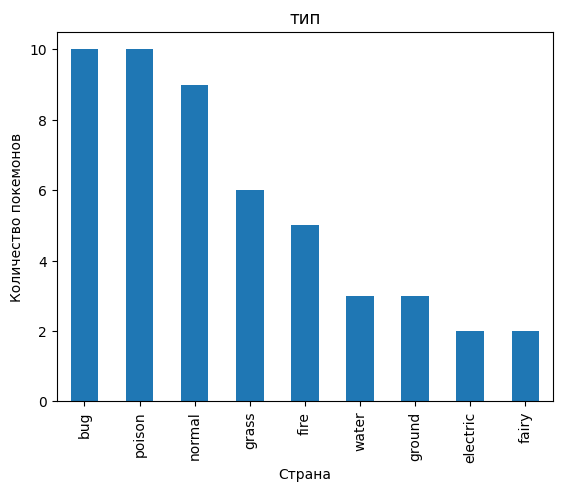

In [28]:
df['primary_type'].value_counts().plot(kind='bar')
plt.title("тип")
plt.xlabel("Страна")
plt.ylabel("Количество покемонов")
plt.show()

In [29]:
def get_pokemon_image(url, size=(50,50)):
    try:
        response = requests.get(url)
        img = Image.open(io.BytesIO(response.content))
        return img.resize(size)
    except:
        return Image.new('RGB', size, color='gray')

<Figure size 1400x800 with 0 Axes>

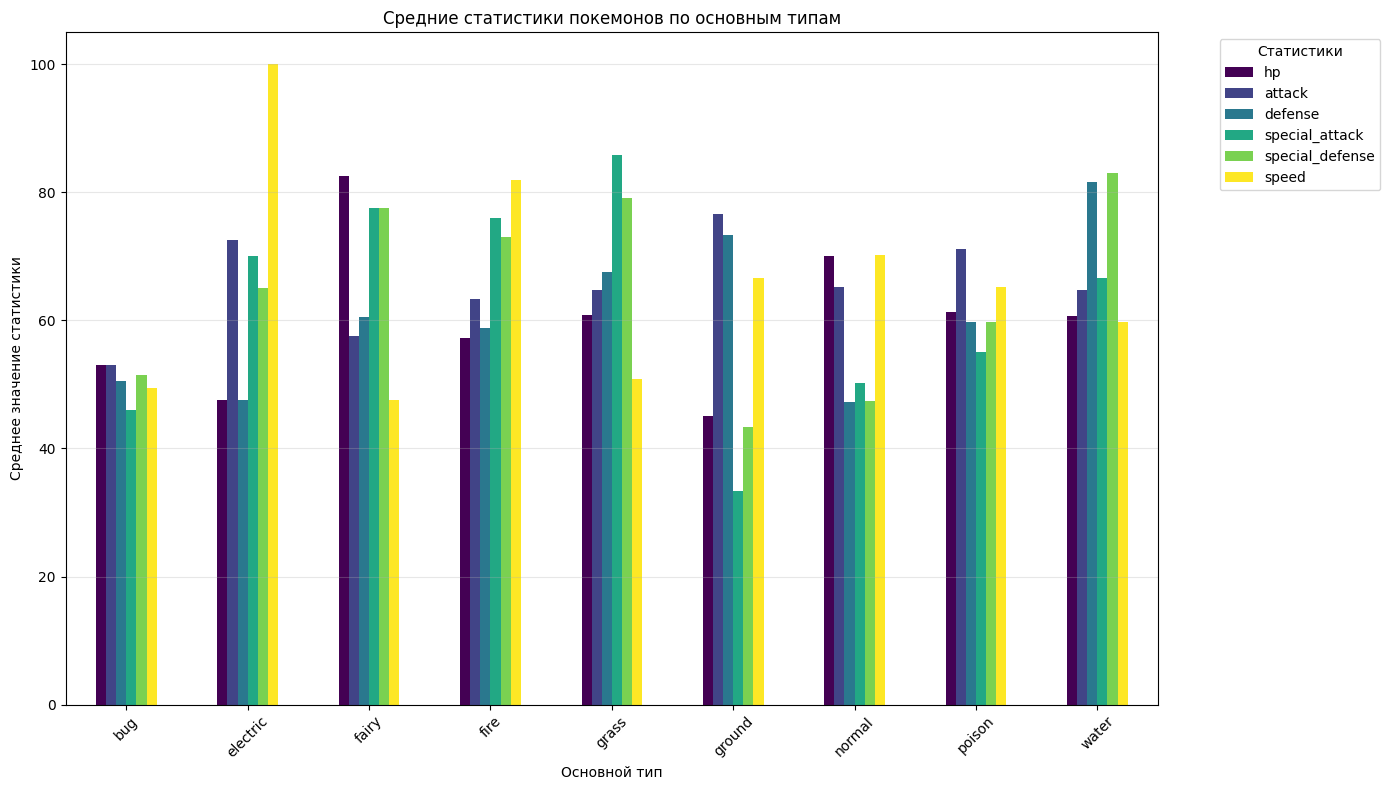

In [30]:
# не знаю можно ли так, нашёл метод в интернете
stats_columns = ['hp', 'attack', 'defense', 'special_attack', 'special_defense', 'speed']
type_avg_stats = df.groupby('primary_type')[stats_columns].mean().round(1)

plt.figure(figsize=(14, 8))
type_avg_stats.plot(kind='bar', figsize=(14, 8), colormap='viridis')
plt.xlabel('Основной тип')
plt.ylabel('Среднее значение статистики')
plt.title('Средние статистики покемонов по основным типам')
plt.xticks(rotation=45)
plt.legend(title='Статистики', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

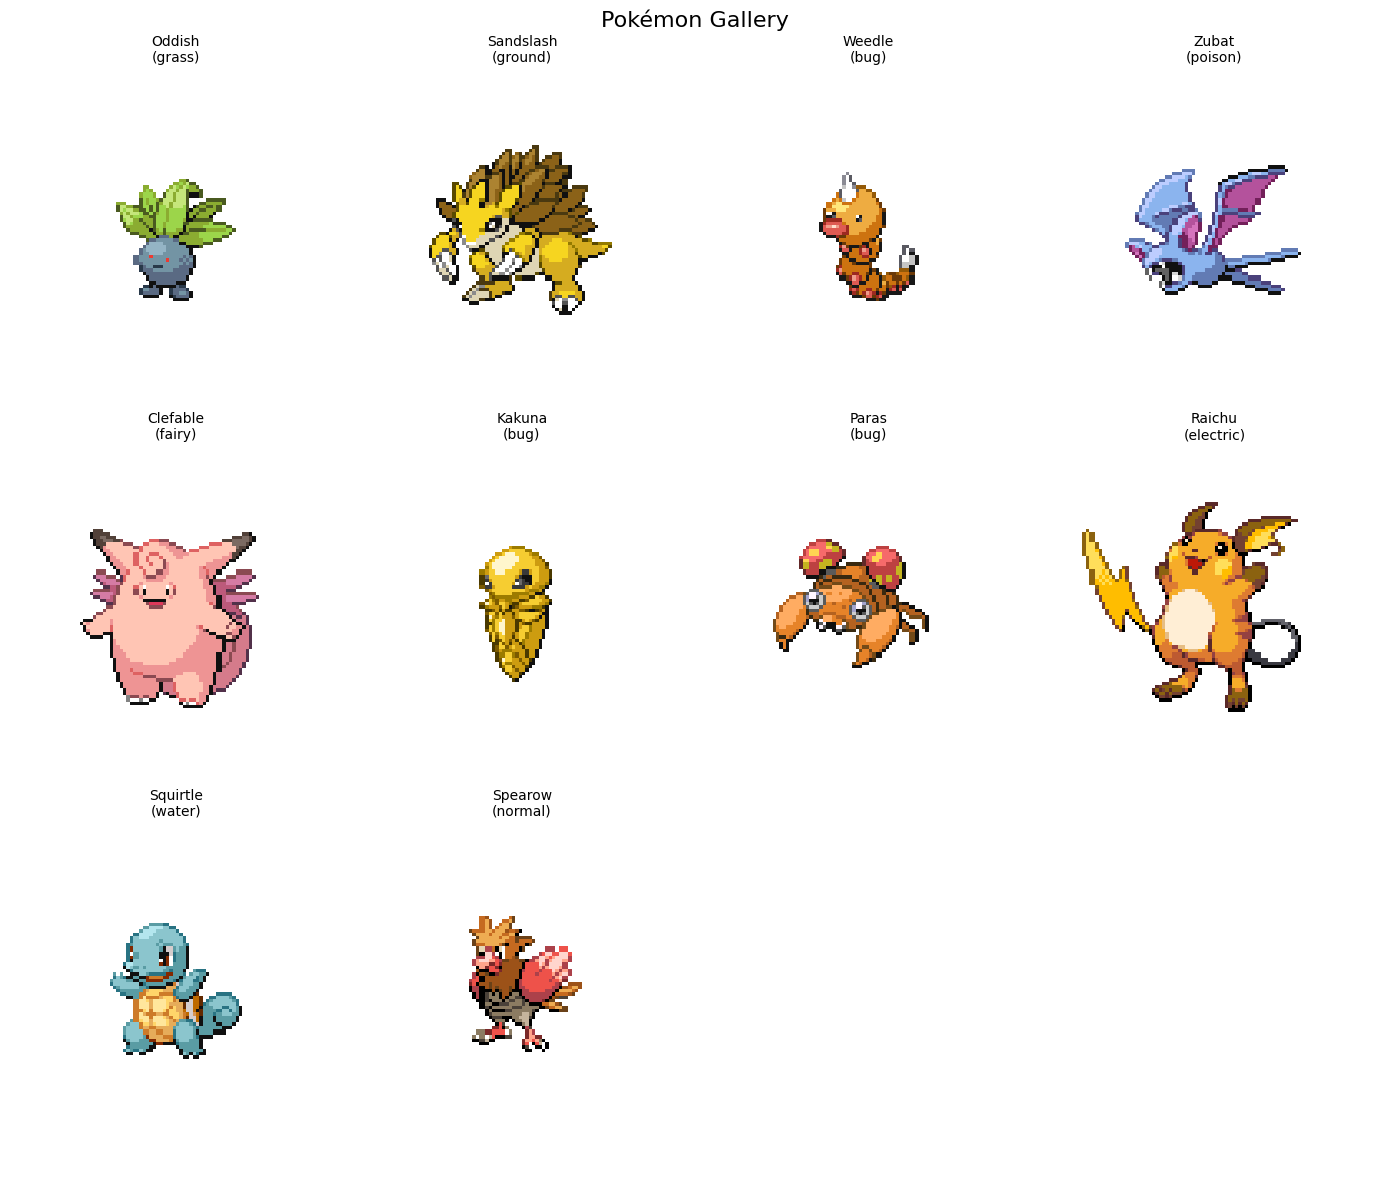

In [23]:
n = 10 
sample_df2 = df.sample(n)
cols, rows = 4, (n + 3)//4
fig, axes = plt.subplots(rows, cols, figsize=(14, 4*rows))
axes = axes.flatten()
for i, (_, pokemon) in enumerate(sample_df2.iterrows()):
    img = get_pokemon_image(pokemon['sprite_url'], size=(100,100))
    axes[i].imshow(img)
    axes[i].set_title(f"{pokemon['name']}\n({pokemon['primary_type']})", fontsize=10)
    axes[i].axis('off')
for j in range(len(sample_df2), len(axes)):
    axes[j].axis('off')
plt.suptitle("Pokémon Gallery", fontsize=16)
plt.tight_layout()
plt.show()